In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data"

DATASET_DIR = DATA_DIR / "sample_dataset"

GRAPH_DB_DIR = DATA_DIR / "chroma_patent_graph_2016"
GRAPH_OUTPUT_DIR = DATA_DIR / "patent_graph_2016"

print("Project directory:", PROJECT_DIR)
print("Dataset exists:", DATASET_DIR.exists())
print("Graph database:", GRAPH_DB_DIR)
print("Graph outputs:", GRAPH_OUTPUT_DIR)

Project directory: /home/patzer_adi/Documents/python/Python_Workspace/Patent_Intelligence_Project
Dataset exists: True
Graph database: /home/patzer_adi/Documents/python/Python_Workspace/Patent_Intelligence_Project/data/chroma_patent_graph_2016
Graph outputs: /home/patzer_adi/Documents/python/Python_Workspace/Patent_Intelligence_Project/data/patent_graph_2016


In [3]:
from datasets import load_from_disk

dataset = load_from_disk(str(DATASET_DIR))

print(dataset)
print("\nTrain records:", len(dataset["train"]))
print("Validation records:", len(dataset["validation"]))

Parameter 'format_kwargs'={} of the transform datasets.arrow_dataset.Dataset.set_format couldn't be hashed properly, a random hash was used instead. Make sure your transforms and parameters are serializable with pickle or dill for the dataset fingerprinting and caching to work. If you reuse this transform, the caching mechanism will consider it to be different from the previous calls and recompute everything. This warning is only showed once. Subsequent hashing failures won't be showed.


DatasetDict({
    train: Dataset({
        features: ['patent_number', 'decision', 'title', 'abstract', 'claims', 'background', 'summary', 'description', 'cpc_label', 'ipc_label', 'filing_date', 'patent_issue_date', 'date_published', 'examiner_id'],
        num_rows: 16153
    })
    validation: Dataset({
        features: ['patent_number', 'decision', 'title', 'abstract', 'claims', 'background', 'summary', 'description', 'cpc_label', 'ipc_label', 'filing_date', 'patent_issue_date', 'date_published', 'examiner_id'],
        num_rows: 9094
    })
})

Train records: 16153
Validation records: 9094


In [4]:
from datasets import concatenate_datasets

train_2016 = dataset["train"].filter(
    lambda row: str(row["date_published"] or "")[:4] == "2016"
)

validation_2016 = dataset["validation"].filter(
    lambda row: str(row["date_published"] or "")[:4] == "2016"
)

patents_2016 = concatenate_datasets(
    [train_2016, validation_2016]
)

print("2016 train records:", len(train_2016))
print("2016 validation records:", len(validation_2016))
print("Total 2016 records:", len(patents_2016))

Filter:   0%|          | 0/16153 [00:00<?, ? examples/s]

Filter:   0%|          | 0/9094 [00:00<?, ? examples/s]

2016 train records: 12706
2016 validation records: 6960
Total 2016 records: 19666


In [5]:
import pandas as pd

df_2016 = patents_2016.to_pandas()

print("Records:", len(df_2016))
print("Missing patent numbers:", df_2016["patent_number"].isna().sum())
print("Duplicate patent numbers:", df_2016["patent_number"].duplicated().sum())

df_2016 = df_2016.drop_duplicates(
    subset="patent_number",
    keep="first"
).reset_index(drop=True)

print("\nUnique 2016 patents:", len(df_2016))

Records: 19666
Missing patent numbers: 0
Duplicate patent numbers: 0

Unique 2016 patents: 19666


In [6]:
import numpy as np

SAMPLE_SIZE = 2500
RANDOM_SEED = 42

df_2016["ipc_class"] = (
    df_2016["ipc_label"]
    .fillna("UNKNOWN")
    .astype(str)
    .str[:3]
)

# Calculate proportional sample allocation per IPC class
class_counts = df_2016["ipc_class"].value_counts()
quotas = class_counts * SAMPLE_SIZE / len(df_2016)

allocation = np.floor(quotas).astype(int)
remaining = SAMPLE_SIZE - allocation.sum()

# Distribute remaining places by largest fractional remainder
remainders = (quotas - allocation).sort_values(ascending=False)

for ipc_class in remainders.index[:remaining]:
    allocation.loc[ipc_class] += 1

# Draw reproducible samples within each class
sample_parts = []

for ipc_class, count in allocation.items():
    if count == 0:
        continue

    group = df_2016[df_2016["ipc_class"] == ipc_class]

    sample_parts.append(
        group.sample(n=count, random_state=RANDOM_SEED)
    )

sample_2016 = (
    pd.concat(sample_parts)
    .sample(frac=1, random_state=RANDOM_SEED)
    .reset_index(drop=True)
)

print("Sample size:", len(sample_2016))
print("Unique patent numbers:", sample_2016["patent_number"].nunique())
print("IPC classes represented:", sample_2016["ipc_class"].nunique())

display(
    sample_2016[
        ["patent_number", "title", "ipc_label", "ipc_class"]
    ].head()
)

Sample size: 2500
Unique patent numbers: 2500
IPC classes represented: 107


,patent_number,title,ipc_label,ipc_class
0,15006410,MOTOR DRIVE HAVING FUNCTION OF DETECTING FAILU...,H02P322,H02
1,15006643,"THIN-FILM TRANSISTOR, ARRAY SUBSTRATE AND DISP...",H01L2712,H01
2,14988443,SEMICONDUCTOR DEVICE,H01L23498,H01
3,14903449,CORROSION PROTECTION SYSTEM AND PUMP DEVICE WI...,C23F1304,C23
4,14906398,Contacting of Electrochromic Devices,G02F1155,G02


In [7]:
import json

sample_dir = GRAPH_OUTPUT_DIR / "samples"
sample_dir.mkdir(parents=True, exist_ok=True)

sample_path = sample_dir / "patents_2016_sample_2500.parquet"
sample_2016.to_parquet(sample_path, index=False)

manifest = {
    "dataset": "HUPD patents published in 2016",
    "population_size": len(df_2016),
    "sample_size": len(sample_2016),
    "random_seed": RANDOM_SEED,
    "sampling_method": "proportional stratified random sampling",
    "stratification_field": "first three characters of ipc_label",
    "embedding_model": "nomic-embed-text:latest",
    "embedding_dimension": 768
}

manifest_path = sample_dir / "sample_manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2))

print("Sample saved:", sample_path)
print("Manifest saved:", manifest_path)
print("Saved records:", len(sample_2016))
print("Unique patent numbers:", sample_2016["patent_number"].nunique())

Sample saved: /home/patzer_adi/Documents/python/Python_Workspace/Patent_Intelligence_Project/data/patent_graph_2016/samples/patents_2016_sample_2500.parquet
Manifest saved: /home/patzer_adi/Documents/python/Python_Workspace/Patent_Intelligence_Project/data/patent_graph_2016/samples/sample_manifest.json
Saved records: 2500
Unique patent numbers: 2500


In [8]:
sample_path = (
    GRAPH_OUTPUT_DIR
    / "samples"
    / "patents_2016_sample_2500.parquet"
)

sample_2016 = pd.read_parquet(sample_path)

print("Loaded records:", len(sample_2016))
print("Unique patent numbers:", sample_2016["patent_number"].nunique())
print("Missing titles:", sample_2016["title"].isna().sum())
print("Missing abstracts:", sample_2016["abstract"].isna().sum())
print("Missing claims:", sample_2016["claims"].isna().sum())
print("Missing descriptions:", sample_2016["description"].isna().sum())

Loaded records: 2500
Unique patent numbers: 2500
Missing titles: 0
Missing abstracts: 0
Missing claims: 0
Missing descriptions: 0


In [9]:
TEXT_FIELDS = [
    "title",
    "abstract",
    "background",
    "summary",
    "claims",
    "description",
]

def build_patent_text(row):
    sections = []

    for field in TEXT_FIELDS:
        value = row[field]

        if pd.notna(value) and str(value).strip():
            sections.append(
                f"{field.upper()}:\n{str(value).strip()}"
            )

    return "\n\n".join(sections)

sample_2016["full_text"] = sample_2016.apply(
    build_patent_text,
    axis=1
)

sample_2016["text_characters"] = (
    sample_2016["full_text"].str.len()
)

print("Patents:", len(sample_2016))
print("Empty documents:", sample_2016["full_text"].eq("").sum())
print("\nText length statistics:")
print(sample_2016["text_characters"].describe())

Patents: 2500
Empty documents: 0

Text length statistics:
count    2.500000e+03
mean     7.583113e+04
std      7.560283e+04
min      9.980000e+02
25%      4.017025e+04
50%      5.848250e+04
75%      8.488500e+04
max      1.477493e+06
Name: text_characters, dtype: float64


In [10]:
text_dir = GRAPH_OUTPUT_DIR / "prepared"
text_dir.mkdir(parents=True, exist_ok=True)

text_path = text_dir / "patents_2016_full_text.parquet"

sample_2016.to_parquet(text_path, index=False)

print("Saved:", text_path)
print("Patents saved:", len(sample_2016))
print("Text fields combined:", TEXT_FIELDS)
print("File size (MB):", round(text_path.stat().st_size / (1024**2), 2))

Saved: /home/patzer_adi/Documents/python/Python_Workspace/Patent_Intelligence_Project/data/patent_graph_2016/prepared/patents_2016_full_text.parquet
Patents saved: 2500
Text fields combined: ['title', 'abstract', 'background', 'summary', 'claims', 'description']
File size (MB): 127.33


In [11]:
import requests

response = requests.post(
    "http://localhost:11434/api/show",
    json={"model": "nomic-embed-text:latest"},
    timeout=30
)

response.raise_for_status()
model_info = response.json()

print("Model:", model_info.get("details", {}).get("family"))
print("Embedding length:", model_info.get("model_info", {}).get(
    "nomic-bert.embedding_length"
))
print("Model parameters:", model_info.get("details", {}).get("parameter_size"))
print("Model information keys:")
print(list(model_info.get("model_info", {}).keys())[:20])

Model: nomic-bert
Embedding length: 768
Model parameters: 137M
Model information keys:
['general.architecture', 'general.file_type', 'general.parameter_count', 'nomic-bert.attention.causal', 'nomic-bert.attention.head_count', 'nomic-bert.attention.layer_norm_epsilon', 'nomic-bert.block_count', 'nomic-bert.context_length', 'nomic-bert.embedding_length', 'nomic-bert.feed_forward_length', 'nomic-bert.pooling_type', 'nomic-bert.rope.freq_base', 'tokenizer.ggml.bos_token_id', 'tokenizer.ggml.cls_token_id', 'tokenizer.ggml.eos_token_id', 'tokenizer.ggml.mask_token_id', 'tokenizer.ggml.model', 'tokenizer.ggml.padding_token_id', 'tokenizer.ggml.scores', 'tokenizer.ggml.seperator_token_id']


In [12]:
context_length = model_info["model_info"].get(
    "nomic-bert.context_length"
)

print("Nomic context length:", context_length, "tokens")

Nomic context length: 2048 tokens


In [13]:
CHUNK_SIZE_TOKENS = 1500
CHUNK_OVERLAP_TOKENS = 200

EMBEDDING_MODEL = "nomic-embed-text:latest"
EMBEDDING_DIMENSION = 768

EMBEDDING_BATCH_SIZE = 8

print("Model:", EMBEDDING_MODEL)
print("Context length:", context_length)
print("Target chunk size:", CHUNK_SIZE_TOKENS)
print("Chunk overlap:", CHUNK_OVERLAP_TOKENS)
print("Batch size:", EMBEDDING_BATCH_SIZE)

Model: nomic-embed-text:latest
Context length: 2048
Target chunk size: 1500
Chunk overlap: 200
Batch size: 8


In [14]:
import pandas as pd

TEXT_PATH = (
    GRAPH_OUTPUT_DIR
    / "prepared"
    / "patents_2016_full_text.parquet"
)

sample_2016 = pd.read_parquet(TEXT_PATH)

test_patent = sample_2016.iloc[0]

print("Patent number:", test_patent["patent_number"])
print("Title:", test_patent["title"])
print("Full text characters:", len(test_patent["full_text"]))
print("\nFirst 500 characters:\n")
print(test_patent["full_text"][:500])

Patent number: 15006410
Title: MOTOR DRIVE HAVING FUNCTION OF DETECTING FAILURE IN DYNAMIC BRAKING CIRCUIT
Full text characters: 34278

First 500 characters:

TITLE:
MOTOR DRIVE HAVING FUNCTION OF DETECTING FAILURE IN DYNAMIC BRAKING CIRCUIT

ABSTRACT:
A motor drive according to the present invention has a dynamic braking circuit. The motor drive includes a motor drive control circuit for applying a voltage to windings of a synchronous motor and the dynamic braking circuit for a predetermined time by switching power transistors connected to a direct current power supply, a current detection circuit for detecting a current value outputted from the powe


In [15]:
import requests
import numpy as np

test_text = test_patent["full_text"][:5000]

response = requests.post(
    "http://localhost:11434/api/embed",
    json={
        "model": EMBEDDING_MODEL,
        "input": f"search_document: {test_text}"
    },
    timeout=120
)

response.raise_for_status()
result = response.json()

test_embedding = np.asarray(
    result["embeddings"][0],
    dtype=np.float32
)

print("Input characters:", len(test_text))
print("Embedding shape:", test_embedding.shape)
print("Embedding finite:", np.isfinite(test_embedding).all())
print("Embedding norm:", round(float(np.linalg.norm(test_embedding)), 4))

Input characters: 5000
Embedding shape: (768,)
Embedding finite: True
Embedding norm: 1.0


In [16]:
CHUNK_SIZE_CHARS = 4000
CHUNK_OVERLAP_CHARS = 400

def chunk_text(text, chunk_size=CHUNK_SIZE_CHARS, overlap=CHUNK_OVERLAP_CHARS):
    text = str(text or "").strip()

    if not text:
        return []

    chunks = []
    start = 0

    while start < len(text):
        end = min(start + chunk_size, len(text))
        chunks.append(text[start:end])

        if end == len(text):
            break

        start = end - overlap

    return chunks

test_chunks = chunk_text(test_patent["full_text"])

print("Patent:", test_patent["patent_number"])
print("Characters:", len(test_patent["full_text"]))
print("Chunks:", len(test_chunks))
print("Chunk lengths:", [len(chunk) for chunk in test_chunks])

Patent: 15006410
Characters: 34278
Chunks: 10
Chunk lengths: [4000, 4000, 4000, 4000, 4000, 4000, 4000, 4000, 4000, 1878]


In [17]:
import requests
import numpy as np

for i, chunk in enumerate(test_chunks[:3]):
    response = requests.post(
        "http://localhost:11434/api/embed",
        json={
            "model": EMBEDDING_MODEL,
            "input": f"search_document: {chunk}"
        },
        timeout=120
    )

    response.raise_for_status()
    result = response.json()

    embedding = np.asarray(
        result["embeddings"][0],
        dtype=np.float32
    )

    print(
        f"Chunk {i}:",
        f"{len(chunk)} characters,",
        f"{embedding.shape[0]} dimensions,",
        f"finite={np.isfinite(embedding).all()}"
    )

Chunk 0: 4000 characters, 768 dimensions, finite=True
Chunk 1: 4000 characters, 768 dimensions, finite=True
Chunk 2: 4000 characters, 768 dimensions, finite=True


In [18]:
CHUNK_SIZE_CHARS = 2000
CHUNK_OVERLAP_CHARS = 200

test_chunks = chunk_text(
    test_patent["full_text"],
    chunk_size=CHUNK_SIZE_CHARS,
    overlap=CHUNK_OVERLAP_CHARS,
)

print("Patent:", test_patent["patent_number"])
print("Chunks:", len(test_chunks))
print("Maximum chunk characters:", max(map(len, test_chunks)))
print("Minimum chunk characters:", min(map(len, test_chunks)))

Patent: 15006410
Chunks: 19
Maximum chunk characters: 2000
Minimum chunk characters: 1878


In [19]:
CHUNK_SIZE_CHARS = 4000
CHUNK_OVERLAP_CHARS = 400

test_chunks = chunk_text(
    test_patent["full_text"],
    chunk_size=CHUNK_SIZE_CHARS,
    overlap=CHUNK_OVERLAP_CHARS,
)

print("Patent:", test_patent["patent_number"])
print("Chunks:", len(test_chunks))
print("Maximum chunk characters:", max(map(len, test_chunks)))
print("Minimum chunk characters:", min(map(len, test_chunks)))

Patent: 15006410
Chunks: 10
Maximum chunk characters: 4000
Minimum chunk characters: 1878


In [20]:
import requests
import numpy as np

chunk_embeddings = []

for i, chunk in enumerate(test_chunks):
    response = requests.post(
        "http://localhost:11434/api/embed",
        json={
            "model": EMBEDDING_MODEL,
            "input": f"search_document: {chunk}"
        },
        timeout=120,
    )
    response.raise_for_status()

    embedding = np.asarray(
        response.json()["embeddings"][0],
        dtype=np.float32,
    )

    chunk_embeddings.append(embedding)

    print(f"Embedded chunk {i + 1}/{len(test_chunks)}")

# Aggregate chunk vectors into one patent-level vector
patent_embedding = np.mean(
    np.stack(chunk_embeddings),
    axis=0,
)

# Normalize the aggregated vector
norm = np.linalg.norm(patent_embedding)
if norm > 0:
    patent_embedding = patent_embedding / norm

print("\nPatent:", test_patent["patent_number"])
print("Chunk embeddings:", len(chunk_embeddings))
print("Patent embedding shape:", patent_embedding.shape)
print("Finite values:", np.isfinite(patent_embedding).all())
print("Norm:", round(float(np.linalg.norm(patent_embedding)), 4))

Embedded chunk 1/10
Embedded chunk 2/10
Embedded chunk 3/10
Embedded chunk 4/10
Embedded chunk 5/10
Embedded chunk 6/10
Embedded chunk 7/10
Embedded chunk 8/10
Embedded chunk 9/10
Embedded chunk 10/10

Patent: 15006410
Chunk embeddings: 10
Patent embedding shape: (768,)
Finite values: True
Norm: 1.0


In [21]:
response = requests.post(
    "http://localhost:11434/api/embed",
    json={
        "model": EMBEDDING_MODEL,
        "input": [
            f"search_document: {chunk}"
            for chunk in test_chunks
        ],
        "truncate": False,
    },
    timeout=120,
)

if response.ok:
    result = response.json()
    print("All chunks accepted:", len(result["embeddings"]) == len(test_chunks))
    print("Embeddings returned:", len(result["embeddings"]))
else:
    print("Status:", response.status_code)
    print(response.text[:1000])

All chunks accepted: True
Embeddings returned: 10


In [22]:
import chromadb

graph_client = chromadb.PersistentClient(path=str(GRAPH_DB_DIR))

graph_collection = graph_client.get_or_create_collection(
    name="patents_2016_sample",
    metadata={
        "description": "Patent-level embeddings for the 2016 similarity graph",
        "embedding_model": EMBEDDING_MODEL,
        "embedding_dimension": EMBEDDING_DIMENSION,
    },
)

print("Graph database:", GRAPH_DB_DIR)
print("Collection:", graph_collection.name)
print("Existing patent embeddings:", graph_collection.count())
print("Target patents:", len(sample_2016))

Graph database: /home/patzer_adi/Documents/python/Python_Workspace/Patent_Intelligence_Project/data/chroma_patent_graph_2016
Collection: patents_2016_sample
Existing patent embeddings: 0
Target patents: 2500


In [23]:
import requests
import numpy as np
import time

CHUNK_SIZE_CHARS = 4000
CHUNK_OVERLAP_CHARS = 400
EMBEDDING_BATCH_SIZE = 1
SAVE_EVERY = 10
REQUEST_TIMEOUT = 120

def chunk_text(text, chunk_size=CHUNK_SIZE_CHARS, overlap=CHUNK_OVERLAP_CHARS):
    text = str(text or "").strip()
    if not text:
        return []

    chunks = []
    start = 0

    while start < len(text):
        end = min(start + chunk_size, len(text))
        chunks.append(text[start:end])

        if end == len(text):
            break

        start = end - overlap

    return chunks


def embed_chunks(chunks):
    vectors = []

    for chunk in chunks:
        response = requests.post(
            "http://localhost:11434/api/embed",
            json={
                "model": EMBEDDING_MODEL,
                "input": f"search_document: {chunk}",
                "truncate": False,
            },
            timeout=REQUEST_TIMEOUT,
        )
        response.raise_for_status()

        embedding = np.asarray(
            response.json()["embeddings"][0],
            dtype=np.float32,
        )

        if embedding.shape != (EMBEDDING_DIMENSION,):
            raise ValueError(f"Unexpected embedding shape: {embedding.shape}")

        if not np.isfinite(embedding).all():
            raise ValueError("Embedding contains non-finite values.")

        vectors.append(embedding)

    patent_vector = np.mean(np.stack(vectors), axis=0)
    norm = np.linalg.norm(patent_vector)

    if norm == 0:
        raise ValueError("Patent embedding has zero norm.")

    return (patent_vector / norm).tolist(), len(chunks)


total = len(sample_2016)
started = time.time()
completed_this_run = 0
failed = []

for position, (_, patent) in enumerate(sample_2016.iterrows(), start=1):
    patent_id = str(patent["patent_number"])

    # Checkpoint: do not repeat patents already stored.
    existing = graph_collection.get(ids=[patent_id], include=[])

    if existing["ids"]:
        continue

    chunks = chunk_text(patent["full_text"])

    if not chunks:
        failed.append((patent_id, "Empty patent text"))
        continue

    try:
        vector, chunk_count = embed_chunks(chunks)

        metadata = {
            "patent_number": patent_id,
            "title": str(patent["title"] or "")[:1000],
            "ipc_label": str(patent["ipc_label"] or "")[:500],
            "cpc_label": str(patent["cpc_label"] or "")[:500],
            "ipc_class": str(patent["ipc_class"]),
            "publication_year": 2016,
            "chunk_count": int(chunk_count),
            "text_characters": int(len(patent["full_text"])),
        }

        # Save immediately after each patent is embedded.
        graph_collection.add(
            ids=[patent_id],
            embeddings=[vector],
            documents=[str(patent["title"] or "")],
            metadatas=[metadata],
        )

        completed_this_run += 1

        if completed_this_run % SAVE_EVERY == 0:
            elapsed = time.time() - started
            print(
                f"Run completed: {completed_this_run} | "
                f"Collection total: {graph_collection.count()} | "
                f"Last position: {position}/{total} | "
                f"Elapsed: {elapsed / 60:.1f} min"
            )

    except Exception as exc:
        failed.append((patent_id, str(exc)))
        print(f"FAILED {patent_id}: {exc}")

print("\nEmbedding run finished.")
print("Collection count:", graph_collection.count())
print("New patents embedded this run:", completed_this_run)
print("Failures:", len(failed))
print("Elapsed minutes:", round((time.time() - started) / 60, 2))

Run completed: 10 | Collection total: 10 | Last position: 10/2500 | Elapsed: 3.3 min
Run completed: 20 | Collection total: 20 | Last position: 20/2500 | Elapsed: 6.5 min
FAILED 14904710: 400 Client Error: Bad Request for url: http://localhost:11434/api/embed
Run completed: 30 | Collection total: 30 | Last position: 31/2500 | Elapsed: 13.9 min
FAILED 14905310: 400 Client Error: Bad Request for url: http://localhost:11434/api/embed
Run completed: 40 | Collection total: 40 | Last position: 42/2500 | Elapsed: 17.3 min


KeyboardInterrupt: 

In [24]:
print("Saved embeddings:", graph_collection.count())
print("Target patents:", len(sample_2016))

Saved embeddings: 42
Target patents: 2500


In [25]:
failed_patent_ids = ["14904710", "14905310"]

for patent_id in failed_patent_ids:
    rows = sample_2016[
        sample_2016["patent_number"].astype(str) == patent_id
    ]

    if rows.empty:
        print(f"{patent_id}: not found in sample")
    else:
        patent = rows.iloc[0]
        chunks = chunk_text(patent["full_text"])
        print(
            f"{patent_id}: "
            f"text={len(patent['full_text']):,} characters, "
            f"chunks={len(chunks)}, "
            f"largest_chunk={max(map(len, chunks), default=0):,} characters"
        )

14904710: text=436,130 characters, chunks=122, largest_chunk=4,000 characters
14905310: text=1,307,157 characters, chunks=363, largest_chunk=4,000 characters


In [26]:
response = requests.post(
    "http://localhost:11434/api/embed",
    json={
        "model": EMBEDDING_MODEL,
        "input": f"search_document: {chunk_text(sample_2016.loc[
            sample_2016['patent_number'].astype(str) == '14904710',
            'full_text'
        ].iloc[0])[0]}",
        "truncate": False,
    },
    timeout=120,
)

print("Status:", response.status_code)
print("Response:", response.text[:2000])

Status: 200
Response: {"model":"nomic-embed-text:latest","embeddings":[[-0.0037908677,0.061815076,-0.14360623,-0.009178987,0.015836263,-0.08682746,-0.054313596,0.03379849,0.0033706774,-0.0076509486,-0.05287027,0.05189387,0.09161348,0.014975987,0.013054963,-0.033210043,0.029957373,-0.0021200972,-0.008963525,0.022286197,-0.13466854,-0.03718834,-0.008424561,-0.076080695,0.05026577,0.024654808,0.021899987,-0.038656697,0.067004204,0.031547092,0.04402491,0.011869373,0.010159085,0.009903578,-0.051184013,-0.050098762,0.051662873,0.049722195,-0.03769626,0.048007853,0.044621035,-0.016987666,0.039195407,-0.048605587,-0.016026242,-0.00013129943,0.038957503,-0.003835903,0.008911097,-0.09236292,0.029076377,0.012287909,0.018434905,-0.09305326,0.09591495,0.00013650623,0.026629314,0.021274878,0.028958958,-0.014193721,0.03519186,0.065447554,0.025330482,0.03439686,0.029909926,-0.02953853,-0.016555395,0.053508684,-0.04840227,-0.009377527,0.059902456,0.012734857,0.049221646,0.018761503,0.0018860676,0.01373

In [27]:
patent_id = "14904710"

patent = sample_2016.loc[
    sample_2016["patent_number"].astype(str) == patent_id
].iloc[0]

chunks = chunk_text(patent["full_text"])

for i, chunk in enumerate(chunks, start=1):
    try:
        response = requests.post(
            "http://localhost:11434/api/embed",
            json={
                "model": EMBEDDING_MODEL,
                "input": f"search_document: {chunk}",
                "truncate": False,
            },
            timeout=120,
        )

        if not response.ok:
            print("Failed chunk:", i, "of", len(chunks))
            print("Status:", response.status_code)
            print("Error:", response.text[:2000])
            break

        print(f"Chunk {i}/{len(chunks)} OK")

    except Exception as exc:
        print("Failed chunk:", i, "of", len(chunks))
        print("Exception:", repr(exc))
        break
else:
    print("All chunks succeeded.")

Chunk 1/122 OK
Chunk 2/122 OK
Chunk 3/122 OK
Chunk 4/122 OK
Chunk 5/122 OK
Chunk 6/122 OK
Chunk 7/122 OK
Chunk 8/122 OK
Chunk 9/122 OK
Chunk 10/122 OK
Chunk 11/122 OK
Chunk 12/122 OK
Chunk 13/122 OK
Chunk 14/122 OK
Chunk 15/122 OK
Chunk 16/122 OK
Chunk 17/122 OK
Chunk 18/122 OK
Chunk 19/122 OK
Chunk 20/122 OK
Chunk 21/122 OK
Chunk 22/122 OK
Chunk 23/122 OK
Chunk 24/122 OK
Chunk 25/122 OK
Chunk 26/122 OK
Chunk 27/122 OK
Chunk 28/122 OK
Chunk 29/122 OK
Chunk 30/122 OK
Chunk 31/122 OK
Chunk 32/122 OK
Chunk 33/122 OK
Chunk 34/122 OK
Chunk 35/122 OK
Chunk 36/122 OK
Chunk 37/122 OK
Chunk 38/122 OK
Chunk 39/122 OK
Chunk 40/122 OK
Chunk 41/122 OK
Chunk 42/122 OK
Chunk 43/122 OK
Chunk 44/122 OK
Chunk 45/122 OK
Chunk 46/122 OK
Chunk 47/122 OK
Chunk 48/122 OK
Chunk 49/122 OK
Chunk 50/122 OK
Chunk 51/122 OK
Chunk 52/122 OK
Chunk 53/122 OK
Chunk 54/122 OK
Chunk 55/122 OK
Chunk 56/122 OK
Chunk 57/122 OK
Chunk 58/122 OK
Chunk 59/122 OK
Chunk 60/122 OK
Chunk 61/122 OK
Chunk 62/122 OK
Chunk 63/122 OK
C

In [28]:
CHUNK_SIZE_CHARS = 1500
CHUNK_OVERLAP_CHARS = 200

patent_id = "14904710"

patent = sample_2016.loc[
    sample_2016["patent_number"].astype(str) == patent_id
].iloc[0]

test_chunks = chunk_text(patent["full_text"])

print("Patent:", patent_id)
print("Chunks:", len(test_chunks))
print("Largest chunk:", max(map(len, test_chunks)), "characters")

Patent: 14904710
Chunks: 122
Largest chunk: 4000 characters


In [29]:
CHUNK_SIZE_CHARS = 1500
CHUNK_OVERLAP_CHARS = 200

def chunk_text(text, chunk_size=CHUNK_SIZE_CHARS, overlap=CHUNK_OVERLAP_CHARS):
    text = str(text or "").strip()
    if not text:
        return []

    chunks = []
    start = 0

    while start < len(text):
        end = min(start + chunk_size, len(text))
        chunks.append(text[start:end])

        if end == len(text):
            break

        start = end - overlap

    return chunks


test_chunks = chunk_text(patent["full_text"])

print("Patent:", patent_id)
print("Chunks:", len(test_chunks))
print("Largest chunk:", max(map(len, test_chunks)), "characters")

Patent: 14904710
Chunks: 336
Largest chunk: 1500 characters


In [30]:
print("Graph collection:", graph_collection.name)
print("Saved embeddings:", graph_collection.count())
print("Graph database:", GRAPH_DB_DIR)
print("Graph outputs:", GRAPH_OUTPUT_DIR)

Graph collection: patents_2016_sample
Saved embeddings: 42
Graph database: /home/patzer_adi/Documents/python/Python_Workspace/Patent_Intelligence_Project/data/chroma_patent_graph_2016
Graph outputs: /home/patzer_adi/Documents/python/Python_Workspace/Patent_Intelligence_Project/data/patent_graph_2016


In [31]:
graph_client.delete_collection(name="patents_2016_sample")

graph_collection = graph_client.get_or_create_collection(
    name="patents_2016_sample",
    metadata={
        "description": "Patent-level embeddings for the 2016 similarity graph",
        "embedding_model": EMBEDDING_MODEL,
        "embedding_dimension": EMBEDDING_DIMENSION,
    },
)

print("Collection reset. Current count:", graph_collection.count())

Collection reset. Current count: 0


In [32]:
CHUNK_SIZE_CHARS = 1500
CHUNK_OVERLAP_CHARS = 200

def chunk_text(text, chunk_size=CHUNK_SIZE_CHARS, overlap=CHUNK_OVERLAP_CHARS):
    text = str(text or "").strip()

    if not text:
        return []

    chunks = []
    start = 0

    while start < len(text):
        end = min(start + chunk_size, len(text))
        chunks.append(text[start:end])

        if end == len(text):
            break

        start = end - overlap

    return chunks

print("Chunk size:", CHUNK_SIZE_CHARS)
print("Overlap:", CHUNK_OVERLAP_CHARS)

Chunk size: 1500
Overlap: 200


In [33]:

import time
import requests
import numpy as np

CHUNK_SIZE_CHARS = 1500
CHUNK_OVERLAP_CHARS = 200
REQUEST_TIMEOUT = 120

def chunk_text(text, chunk_size=CHUNK_SIZE_CHARS, overlap=CHUNK_OVERLAP_CHARS):
    text = str(text or "").strip()
    if not text:
        return []

    chunks = []
    start = 0

    while start < len(text):
        end = min(start + chunk_size, len(text))
        chunks.append(text[start:end])

        if end == len(text):
            break

        start = end - overlap

    return chunks


def embed_chunks(chunks):
    vectors = []

    for chunk in chunks:
        response = requests.post(
            "http://localhost:11434/api/embed",
            json={
                "model": EMBEDDING_MODEL,
                "input": f"search_document: {chunk}",
                "truncate": False,
            },
            timeout=REQUEST_TIMEOUT,
        )
        response.raise_for_status()

        embedding = np.asarray(
            response.json()["embeddings"][0],
            dtype=np.float32,
        )

        if embedding.shape != (EMBEDDING_DIMENSION,):
            raise ValueError(f"Unexpected embedding shape: {embedding.shape}")

        if not np.isfinite(embedding).all():
            raise ValueError("Embedding contains non-finite values.")

        vectors.append(embedding)

    vector = np.mean(np.stack(vectors), axis=0)
    norm = np.linalg.norm(vector)

    if norm == 0:
        raise ValueError("Patent embedding has zero norm.")

    return (vector / norm).tolist(), len(chunks)


total = len(sample_2016)
started = time.time()
completed = 0
failed = []

for position, (_, patent) in enumerate(sample_2016.iterrows(), start=1):
    patent_id = str(patent["patent_number"])

    existing = graph_collection.get(ids=[patent_id], include=[])

    if existing["ids"]:
        continue

    chunks = chunk_text(patent["full_text"])

    if not chunks:
        failed.append((patent_id, "Empty patent text"))
        continue

    try:
        vector, chunk_count = embed_chunks(chunks)

        def safe_text(value, limit=1000):
            return str(value)[:limit] if value is not None else ""

        metadata = {
            "patent_number": patent_id,
            "title": safe_text(patent["title"]),
            "ipc_label": safe_text(patent["ipc_label"], 500),
            "cpc_label": safe_text(patent["cpc_label"], 500),
            "ipc_class": safe_text(patent["ipc_class"], 100),
            "publication_year": 2016,
            "chunk_count": int(chunk_count),
            "text_characters": int(len(patent["full_text"])),
        }

        graph_collection.add(
            ids=[patent_id],
            embeddings=[vector],
            documents=[safe_text(patent["title"])],
            metadatas=[metadata],
        )

        completed += 1

        if completed % 10 == 0:
            print(
                f"Newly embedded: {completed} | "
                f"Collection total: {graph_collection.count()} | "
                f"Position: {position}/{total} | "
                f"Elapsed: {(time.time() - started) / 60:.1f} min",
                flush=True,
            )

    except Exception as exc:
        failed.append((patent_id, str(exc)))
        print(
            f"FAILED {patent_id}: {exc}",
            flush=True,
        )

print("\nEmbedding run finished.")
print("Collection total:", graph_collection.count())
print("New embeddings this run:", completed)
print("Failed patents:", len(failed))
print("Elapsed minutes:", round((time.time() - started) / 60, 2))


Newly embedded: 10 | Collection total: 10 | Position: 10/2500 | Elapsed: 3.3 min


KeyboardInterrupt: 

In [35]:
import torch
from sentence_transformers import SentenceTransformer

MODEL_NAME = "nomic-ai/nomic-embed-text-v1.5"

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

embedding_model = SentenceTransformer(
    MODEL_NAME,
    device="cpu",
    trust_remote_code=True,
)

print("Model loaded:", MODEL_NAME)
print("Embedding dimension:", embedding_model.get_sentence_embedding_dimension())

PyTorch version: 2.14.1+cpu
CUDA available: False


model.safetensors: reconstructing file:   0%|          |  0.00B /  547MB            

model.safetensors: downloading bytes:           |  0.00B            

<All keys matched successfully>


config.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

Model loaded: nomic-ai/nomic-embed-text-v1.5
Embedding dimension: 768


/tmp/ipykernel_2749/3495684279.py:16: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Embedding dimension:", embedding_model.get_sentence_embedding_dimension())


In [36]:
print("Model loaded:", "embedding_model" in globals())

if "embedding_model" in globals():
    print("Dimensions:", embedding_model.get_sentence_embedding_dimension())
    print("Device:", embedding_model.device)

Model loaded: True
Dimensions: 768
Device: cpu


/tmp/ipykernel_2749/4057033497.py:4: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Dimensions:", embedding_model.get_sentence_embedding_dimension())


In [38]:
import transformers
import sentence_transformers
import torch

print("Transformers:", transformers.__version__)
print("Sentence Transformers:", sentence_transformers.__version__)
print("PyTorch:", torch.__version__)
print("Model:", embedding_model)

Transformers: 5.17.0
Sentence Transformers: 6.1.0
PyTorch: 2.14.1+cpu
Model: SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'NomicBertModel'})
  (1): Pooling({'embedding_dimension': 768, 'pooling_mode': 'mean', 'include_prompt': True})
)


In [39]:
print("Saved embeddings:", graph_collection.count())
print("Target patents:", len(sample_2016))
print("Ollama model:", EMBEDDING_MODEL)
print("Chunk size:", CHUNK_SIZE_CHARS)
print("Chunk overlap:", CHUNK_OVERLAP_CHARS)

Saved embeddings: 14
Target patents: 2500
Ollama model: nomic-embed-text:latest
Chunk size: 1500
Chunk overlap: 200


In [40]:

import json
import time
import requests
import numpy as np
from pathlib import Path

# ---------- Configuration ----------
CHUNK_SIZE_CHARS = 1500
CHUNK_OVERLAP_CHARS = 200
REQUEST_TIMEOUT = 120
LOG_EVERY = 10

OLLAMA_URL = "http://localhost:11434/api/embed"

GRAPH_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FAILURE_LOG = GRAPH_OUTPUT_DIR / "embedding_failures.jsonl"
PROGRESS_LOG = GRAPH_OUTPUT_DIR / "embedding_progress.jsonl"


# ---------- Text chunking ----------
def chunk_text(text, chunk_size=CHUNK_SIZE_CHARS, overlap=CHUNK_OVERLAP_CHARS):
    text = str(text or "").strip()

    if not text:
        return []

    chunks = []
    start = 0

    while start < len(text):
        end = min(start + chunk_size, len(text))
        chunks.append(text[start:end])

        if end == len(text):
            break

        start = end - overlap

    return chunks


# ---------- Embed all chunks of one patent ----------
def embed_patent_chunks(chunks):
    vectors = []

    for chunk_index, chunk in enumerate(chunks, start=1):
        response = requests.post(
            OLLAMA_URL,
            json={
                "model": EMBEDDING_MODEL,
                "input": f"search_document: {chunk}",
                "truncate": False,
            },
            timeout=REQUEST_TIMEOUT,
        )
        response.raise_for_status()

        vector = np.asarray(
            response.json()["embeddings"][0],
            dtype=np.float32,
        )

        if vector.shape != (EMBEDDING_DIMENSION,):
            raise ValueError(
                f"Unexpected embedding shape: {vector.shape}"
            )

        if not np.isfinite(vector).all():
            raise ValueError("Embedding contains non-finite values.")

        vectors.append(vector)

    # One vector per patent: mean of chunk vectors, then normalization.
    patent_vector = np.mean(np.stack(vectors), axis=0)
    norm = np.linalg.norm(patent_vector)

    if norm == 0:
        raise ValueError("Patent embedding has zero norm.")

    return (patent_vector / norm).tolist(), len(chunks)


# ---------- Run with persistent progress ----------
started = time.time()
newly_saved = 0
failed_count = 0
skipped_count = 0
total = len(sample_2016)

print("=" * 55, flush=True)
print("PATENT EMBEDDING RUN STARTED", flush=True)
print("Model:", EMBEDDING_MODEL, flush=True)
print("Target patents:", total, flush=True)
print("Chunk size:", CHUNK_SIZE_CHARS, flush=True)
print("Chunk overlap:", CHUNK_OVERLAP_CHARS, flush=True)
print("Already saved:", graph_collection.count(), flush=True)
print("=" * 55, flush=True)

for position, (_, patent) in enumerate(sample_2016.iterrows(), start=1):
    patent_id = str(patent["patent_number"])

    # Resume support: skip patents already stored in ChromaDB.
    if graph_collection.get(ids=[patent_id], include=[])["ids"]:
        skipped_count += 1
        continue

    try:
        chunks = chunk_text(patent["full_text"])

        if not chunks:
            raise ValueError("Empty patent text")

        vector, chunk_count = embed_patent_chunks(chunks)

        def metadata_text(value, limit=500):
            return "" if value is None else str(value)[:limit]

        metadata = {
            "patent_number": patent_id,
            "title": metadata_text(patent["title"], 1000),
            "ipc_label": metadata_text(patent["ipc_label"]),
            "cpc_label": metadata_text(patent["cpc_label"]),
            "ipc_class": metadata_text(patent["ipc_class"], 100),
            "publication_year": 2016,
            "chunk_count": int(chunk_count),
            "text_characters": int(len(patent["full_text"])),
        }

        # Persist each completed patent immediately.
        graph_collection.add(
            ids=[patent_id],
            embeddings=[vector],
            documents=[metadata["title"]],
            metadatas=[metadata],
        )

        newly_saved += 1

        # Persist a checkpoint after every successful patent.
        with PROGRESS_LOG.open("a", encoding="utf-8") as log:
            log.write(json.dumps({
                "patent_id": patent_id,
                "position": position,
                "collection_count": graph_collection.count(),
                "timestamp": time.time(),
            }) + "\n")

        if newly_saved % LOG_EVERY == 0:
            elapsed = time.time() - started
            saved_total = graph_collection.count()
            scanned_percent = position / total * 100

            print(f"\nProgress: {position}/{total} scanned "
                  f"({scanned_percent:.2f}%)", flush=True)
            print(f"Newly embedded this run: {newly_saved}", flush=True)
            print(f"Total saved in ChromaDB: {saved_total}", flush=True)
            print(f"Failed patents this run: {failed_count}", flush=True)
            print(f"Skipped already-saved patents: {skipped_count}", flush=True)
            print(f"Elapsed: {elapsed / 60:.1f} minutes", flush=True)
            print("-" * 55, flush=True)

    except Exception as exc:
        failed_count += 1

        error_record = {
            "patent_id": patent_id,
            "position": position,
            "error": str(exc),
            "timestamp": time.time(),
        }

        # Record failures on disk immediately.
        with FAILURE_LOG.open("a", encoding="utf-8") as log:
            log.write(json.dumps(error_record) + "\n")

        print(
            f"\nFAILED patent {patent_id} "
            f"at position {position}/{total}: {exc}",
            flush=True,
        )

# ---------- Final summary ----------
elapsed = time.time() - started

print("\n" + "=" * 55, flush=True)
print("EMBEDDING RUN FINISHED", flush=True)
print("Patents in sample:", total, flush=True)
print("Total saved in ChromaDB:", graph_collection.count(), flush=True)
print("New embeddings this run:", newly_saved, flush=True)
print("Skipped already-saved:", skipped_count, flush=True)
print("Failures this run:", failed_count, flush=True)
print(f"Elapsed time: {elapsed / 60:.1f} minutes", flush=True)
print("Failure log:", FAILURE_LOG, flush=True)
print("Progress log:", PROGRESS_LOG, flush=True)
print("=" * 55, flush=True)


PATENT EMBEDDING RUN STARTED
Model: nomic-embed-text:latest
Target patents: 2500
Chunk size: 1500
Chunk overlap: 200
Already saved: 14

Progress: 24/2500 scanned (0.96%)
Newly embedded this run: 10
Total saved in ChromaDB: 24
Failed patents this run: 0
Skipped already-saved patents: 14
Elapsed: 4.1 minutes
-------------------------------------------------------

Progress: 34/2500 scanned (1.36%)
Newly embedded this run: 20
Total saved in ChromaDB: 34
Failed patents this run: 0
Skipped already-saved patents: 14
Elapsed: 11.5 minutes
-------------------------------------------------------

Progress: 44/2500 scanned (1.76%)
Newly embedded this run: 30
Total saved in ChromaDB: 44
Failed patents this run: 0
Skipped already-saved patents: 14
Elapsed: 29.2 minutes
-------------------------------------------------------

Progress: 54/2500 scanned (2.16%)
Newly embedded this run: 40
Total saved in ChromaDB: 54
Failed patents this run: 0
Skipped already-saved patents: 14
Elapsed: 33.5 minutes
--

In [2]:
from pathlib import Path
import chromadb

print("Notebook working directory:")
print(Path.cwd())

db_path = Path("data/chroma_patent_graph_2016").resolve()
print("\nDatabase path being checked:")
print(db_path)
print("Path exists:", db_path.exists())

client = chromadb.PersistentClient(path=str(db_path))
print("\nCollections in this database:")
print(client.list_collections())

Notebook working directory:
/home/patzer_adi/Documents/python/Python_Workspace/Patent_Intelligence_Project/notebooks

Database path being checked:
/home/patzer_adi/Documents/python/Python_Workspace/Patent_Intelligence_Project/notebooks/data/chroma_patent_graph_2016
Path exists: True

Collections in this database:
[]


In [3]:
from pathlib import Path
import chromadb

PROJECT_DIR = Path.cwd().parent
GRAPH_DB_DIR = PROJECT_DIR / "data" / "chroma_patent_graph_2016"

print("Database path:", GRAPH_DB_DIR)

graph_client = chromadb.PersistentClient(
    path=str(GRAPH_DB_DIR)
)

graph_collection = graph_client.get_collection(
    "patents_2016_sample"
)

print("Collection:", graph_collection.name)
print("Saved embeddings:", graph_collection.count())

assert graph_collection.count() == 2500
print("VERIFICATION PASSED")

Database path: /home/patzer_adi/Documents/python/Python_Workspace/Patent_Intelligence_Project/data/chroma_patent_graph_2016
Collection: patents_2016_sample
Saved embeddings: 2500
VERIFICATION PASSED


In [4]:
import numpy as np
from pathlib import Path
import chromadb

# Project and database paths
PROJECT_DIR = Path.cwd().parent
GRAPH_DB_DIR = PROJECT_DIR / "data" / "chroma_patent_graph_2016"
GRAPH_OUTPUT_DIR = PROJECT_DIR / "data" / "patent_graph_2016"

# Open the correct collection
graph_client = chromadb.PersistentClient(
    path=str(GRAPH_DB_DIR)
)
graph_collection = graph_client.get_collection(
    "patents_2016_sample"
)

# Load all patent IDs, embeddings, and metadata
data = graph_collection.get(
    include=["embeddings", "metadatas", "documents"]
)

patent_ids = np.asarray(data["ids"])
embeddings = np.asarray(data["embeddings"], dtype=np.float32)
patent_metadata = data["metadatas"]

# Validate
print("Number of patents:", len(patent_ids))
print("Embedding matrix shape:", embeddings.shape)
print("Unique patent IDs:", len(set(patent_ids)))
print("Missing embeddings:", np.isnan(embeddings).any())
print("Infinite values:", np.isinf(embeddings).any())
print("Output directory:", GRAPH_OUTPUT_DIR)

assert len(patent_ids) == 2500
assert embeddings.shape == (2500, 768)
assert len(set(patent_ids)) == 2500
assert np.isfinite(embeddings).all()

print("\nEmbedding data loaded and validated.")

Number of patents: 2500
Embedding matrix shape: (2500, 768)
Unique patent IDs: 2500
Missing embeddings: False
Infinite values: False
Output directory: /home/patzer_adi/Documents/python/Python_Workspace/Patent_Intelligence_Project/data/patent_graph_2016

Embedding data loaded and validated.


In [5]:
# Calculate pairwise cosine similarities
similarity_matrix = embeddings @ embeddings.T

# Correct tiny floating-point asymmetries
similarity_matrix = (
    similarity_matrix + similarity_matrix.T
) / 2

# Similarity of a patent with itself is 1
np.fill_diagonal(similarity_matrix, 1.0)

print("Similarity matrix shape:", similarity_matrix.shape)
print("Minimum similarity:", similarity_matrix.min())
print("Maximum similarity:", similarity_matrix.max())
print("All values finite:", np.isfinite(similarity_matrix).all())

# Inspect a few pairs
print("\nSimilarities for the first patent:")
print(np.round(similarity_matrix[0, 1:11], 4))

assert similarity_matrix.shape == (2500, 2500)
assert np.isfinite(similarity_matrix).all()

print("\nCosine similarity calculation complete.")

Similarity matrix shape: (2500, 2500)
Minimum similarity: 0.5445125
Maximum similarity: 1.0
All values finite: True

Similarities for the first patent:
[0.7822 0.7839 0.7651 0.7265 0.8243 0.6928 0.7398 0.7524 0.7307 0.7436]

Cosine similarity calculation complete.


In [6]:
import networkx as nx
import numpy as np

K = 10
n = len(patent_ids)

# Exclude self-similarity when finding nearest neighbours
similarities = similarity_matrix.copy()
np.fill_diagonal(similarities, -np.inf)

# Indices of each patent's K nearest neighbours
nearest_indices = np.argpartition(
    similarities, -K, axis=1
)[:, -K:]

# Sort each row's selected neighbours by similarity
rows = np.arange(n)[:, None]
nearest_indices = nearest_indices[
    rows,
    np.argsort(similarities[rows, nearest_indices], axis=1)[:, ::-1]
]

# Build an undirected, weighted graph
G = nx.Graph()

for i, patent_id in enumerate(patent_ids):
    G.add_node(
        str(patent_id),
        **{
            key: value
            for key, value in patent_metadata[i].items()
            if value is not None
        }
    )

for i in range(n):
    for j in nearest_indices[i]:
        G.add_edge(
            str(patent_ids[i]),
            str(patent_ids[j]),
            weight=float(similarity_matrix[i, j])
        )

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Directed neighbour selections:", n * K)
print("Average degree:", round(
    sum(dict(G.degree()).values()) / n, 2
))
print("Connected components:", nx.number_connected_components(G))
print("Graph density:", round(nx.density(G), 6))

print("\nGraph constructed successfully.")

Nodes: 2500
Edges: 20764
Directed neighbour selections: 25000
Average degree: 16.61
Connected components: 1
Graph density: 0.006647

Graph constructed successfully.


In [7]:
import pandas as pd
import numpy as np

edge_weights = np.array([
    attributes["weight"]
    for _, _, attributes in G.edges(data=True)
])

print("Number of edges:", len(edge_weights))
print("\nEdge similarity statistics:")
print(pd.Series(edge_weights).describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).round(4))

print("\nWeakest 10 edges:")
print(np.sort(edge_weights)[:10])

print("\nStrongest 10 edges:")
print(np.sort(edge_weights)[-10:][::-1])

Number of edges: 20764

Edge similarity statistics:
count    20764.0000
mean         0.8956
std          0.0270
min          0.7618
10%          0.8617
25%          0.8778
50%          0.8955
75%          0.9137
90%          0.9292
95%          0.9392
99%          0.9610
max          0.9995
dtype: float64

Weakest 10 edges:
[0.76179808 0.76591825 0.76816905 0.77154756 0.77155894 0.77185035
 0.77880365 0.77993053 0.78061259 0.78294033]

Strongest 10 edges:
[0.99951458 0.99937773 0.99910963 0.99893284 0.99890834 0.99873418
 0.99854064 0.99848282 0.99828517 0.99824011]


In [8]:
import pandas as pd

strongest_edges = sorted(
    G.edges(data=True),
    key=lambda edge: edge[2]["weight"],
    reverse=True
)[:15]

rows = []

for patent_a, patent_b, attributes in strongest_edges:
    a = G.nodes[patent_a]
    b = G.nodes[patent_b]

    rows.append({
        "similarity": round(attributes["weight"], 4),
        "patent_A": patent_a,
        "title_A": a.get("title", ""),
        "IPC_A": a.get("ipc_label", ""),
        "patent_B": patent_b,
        "title_B": b.get("title", ""),
        "IPC_B": b.get("ipc_label", ""),
    })

strongest_pairs_df = pd.DataFrame(rows)

with pd.option_context(
    "display.max_colwidth", 100,
    "display.width", 220
):
    display(strongest_pairs_df)

,similarity,patent_A,title_A,IPC_A,patent_B,title_B,IPC_B
0,0.9995,14993385,AUTHORING TOOL FOR THE AUTHORING OF WRAP PACKAGES OF CARDS,G06Q3002,14993264,AUTHORING TOOL FOR THE AUTHORING OF WRAP PACKAGES OF CARDS,G06F1724
1,0.9994,14989674,IMPLANTABLE HEAD LOCATED RADIOFREQUENCY COUPLED NEUROSTIMULATION SYSTEM FOR HEAD PAIN,A61N1378,14990654,IMPLANTABLE HEAD LOCATED RADIOFREQUENCY COUPLED NEUROSTIMULATION SYSTEM FOR HEAD PAIN,A61N1378
2,0.9991,14995011,POTENTIATION OF FIXED COPPERS AND OTHER PESTICIDES CONTAINING COPPER AND SUPPLEMENTING PLANT NUT...,A01N5920,15005936,POTENTIATION OF FIXED COPPERS AND OTHER PESTICIDES CONTAINING COPPER AND SUPPLEMENTING PLANT NUT...,C05G302
3,0.9989,15010546,IMAGE PROCESSING METHOD AND IMAGE PROCESSING APPARATUS,H04N1982,15010499,IMAGE PROCESSING METHOD AND IMAGE PROCESSING APPARATUS,H04N1982
4,0.9989,15007822,TRANSPORTATION SYSTEM,B61B1310,15007452,TRANSPORTATION SYSTEM,B61B1310
5,0.9987,14986678,DYNAMIC CORE SELECTION FOR HETEROGENEOUS MULTI-CORE SYSTEMS,G06F132,14986677,DYNAMIC CORE SELECTION FOR HETEROGENEOUS MULTI-CORE SYSTEMS,G06F132
6,0.9985,15009667,ANTI-TRANSTHYRETIN ANTIBODIES,C07K1618,15009666,ANTI-TRANSTHYRETIN ANTIBODIES,C07K1618
7,0.9985,14904669,Tire Having A Softened Carcass Reinforcement,B60C922,14904664,Tire Comprising Variable Thicknesses Of The Rubber Mixtures Inside The Carcass Reinforcement,B60C920
8,0.9983,14996181,ALIGNMENT OF PACKETS FOR IMPLEMENTING COEXISTENCE OF MULTIPLE HOMOGENEOUS RADIOS,H04W7208,15004088,CHANNEL STEERING FOR IMPLEMENTING COEXISTENCE OF MULTIPLE HOMOGENEOUS RADIOS,H04W2402
9,0.9982,14991278,Portable Corneal Topographer,A61B3107,14991055,Portable Wavefront Aberrometer with Open Field Alignment Channel,A61B310


In [10]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd().parent
SAMPLE_PATH = (
    PROJECT_DIR
    / "data"
    / "patent_graph_2016"
    / "samples"
    / "patents_2016_sample_2500.parquet"
)

print("Loading from:", SAMPLE_PATH)
print("File exists:", SAMPLE_PATH.exists())

sample_2016 = pd.read_parquet(SAMPLE_PATH)

print("Sample shape:", sample_2016.shape)
print("Columns:", sample_2016.columns.tolist())

Loading from: /home/patzer_adi/Documents/python/Python_Workspace/Patent_Intelligence_Project/data/patent_graph_2016/samples/patents_2016_sample_2500.parquet
File exists: True
Sample shape: (2500, 15)
Columns: ['patent_number', 'decision', 'title', 'abstract', 'claims', 'background', 'summary', 'description', 'cpc_label', 'ipc_label', 'filing_date', 'patent_issue_date', 'date_published', 'examiner_id', 'ipc_class']


In [11]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd().parent
SAMPLE_PATH = (
    PROJECT_DIR
    / "data"
    / "patent_graph_2016"
    / "samples"
    / "patents_2016_sample_2500.parquet"
)

print("Loading from:", SAMPLE_PATH)
print("File exists:", SAMPLE_PATH.exists())

sample_2016 = pd.read_parquet(SAMPLE_PATH)

print("Sample shape:", sample_2016.shape)
print("Columns:", sample_2016.columns.tolist())

Loading from: /home/patzer_adi/Documents/python/Python_Workspace/Patent_Intelligence_Project/data/patent_graph_2016/samples/patents_2016_sample_2500.parquet
File exists: True
Sample shape: (2500, 15)
Columns: ['patent_number', 'decision', 'title', 'abstract', 'claims', 'background', 'summary', 'description', 'cpc_label', 'ipc_label', 'filing_date', 'patent_issue_date', 'date_published', 'examiner_id', 'ipc_class']


In [12]:
from IPython.display import display
import pandas as pd

pairs_to_inspect = [
    ("14993385", "14993264"),
    ("14989674", "14990654"),
]

patent_lookup = sample_2016.copy()
patent_lookup["patent_number"] = (
    patent_lookup["patent_number"].astype(str)
)
patent_lookup = patent_lookup.set_index("patent_number")

for patent_a, patent_b in pairs_to_inspect:
    print("\n" + "=" * 80)
    print(f"PATENT PAIR: {patent_a} vs {patent_b}")
    print("=" * 80)

    for patent_id in [patent_a, patent_b]:
        if patent_id not in patent_lookup.index:
            print(f"Patent {patent_id} not found in sample.")
            continue

        patent = patent_lookup.loc[patent_id]

        print(f"\nPatent: {patent_id}")
        print("Title:", patent["title"])
        print("IPC:", patent["ipc_label"])

        for field in ["abstract", "claims"]:
            text = str(patent.get(field, ""))
            print(f"\n{field.upper()} (first 1500 characters):")
            print(text[:1500])


PATENT PAIR: 14993385 vs 14993264

Patent: 14993385
Title: AUTHORING TOOL FOR THE AUTHORING OF WRAP PACKAGES OF CARDS
IPC: G06Q3002

ABSTRACT (first 1500 characters):
An authoring tool for authoring wrap packages of cards. The authoring tool includes a set of tools that enable an author to create a new card of a wrap selected from a variety of card templates. In various embodiments, the card templates include textual, video, image/photo, document, gallery, chat, widgets, global components, location/GPS, transact, appointment, and end-of-wrap card templates. When a particular card template is selected, the template is then duplicated to create the new card. Thereafter, the author may author the card to include various components, content, attributes, layouts, styles triggers and/or behaviors. As the cards of the wrap are created, the authoring tool provides the author with the ability to order the sequence of the cards. The authoring tool thus enables authors to selectively create wrap

In [13]:
import json
import networkx as nx
import pandas as pd

from pathlib import Path

PROJECT_DIR = Path.cwd().parent
GRAPH_OUTPUT_DIR = (
    PROJECT_DIR / "data" / "patent_graph_2016"
)
GRAPH_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the graph, preserving node attributes and edge weights
graph_path = GRAPH_OUTPUT_DIR / "patent_similarity_graph.graphml"
nx.write_graphml(G, graph_path)

# Save the edge list as CSV
edges_df = nx.to_pandas_edgelist(G)
edges_path = GRAPH_OUTPUT_DIR / "patent_similarity_edges.csv"
edges_df.to_csv(edges_path, index=False)

# Save node metadata as CSV
nodes_df = pd.DataFrame.from_dict(
    dict(G.nodes(data=True)),
    orient="index"
)
nodes_df.index.name = "patent_number"
nodes_path = GRAPH_OUTPUT_DIR / "patent_similarity_nodes.csv"
nodes_df.to_csv(nodes_path)

print("Graph saved:", graph_path)
print("Edges saved:", edges_path)
print("Nodes saved:", nodes_path)
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

Graph saved: /home/patzer_adi/Documents/python/Python_Workspace/Patent_Intelligence_Project/data/patent_graph_2016/patent_similarity_graph.graphml
Edges saved: /home/patzer_adi/Documents/python/Python_Workspace/Patent_Intelligence_Project/data/patent_graph_2016/patent_similarity_edges.csv
Nodes saved: /home/patzer_adi/Documents/python/Python_Workspace/Patent_Intelligence_Project/data/patent_graph_2016/patent_similarity_nodes.csv
Nodes: 2500
Edges: 20764


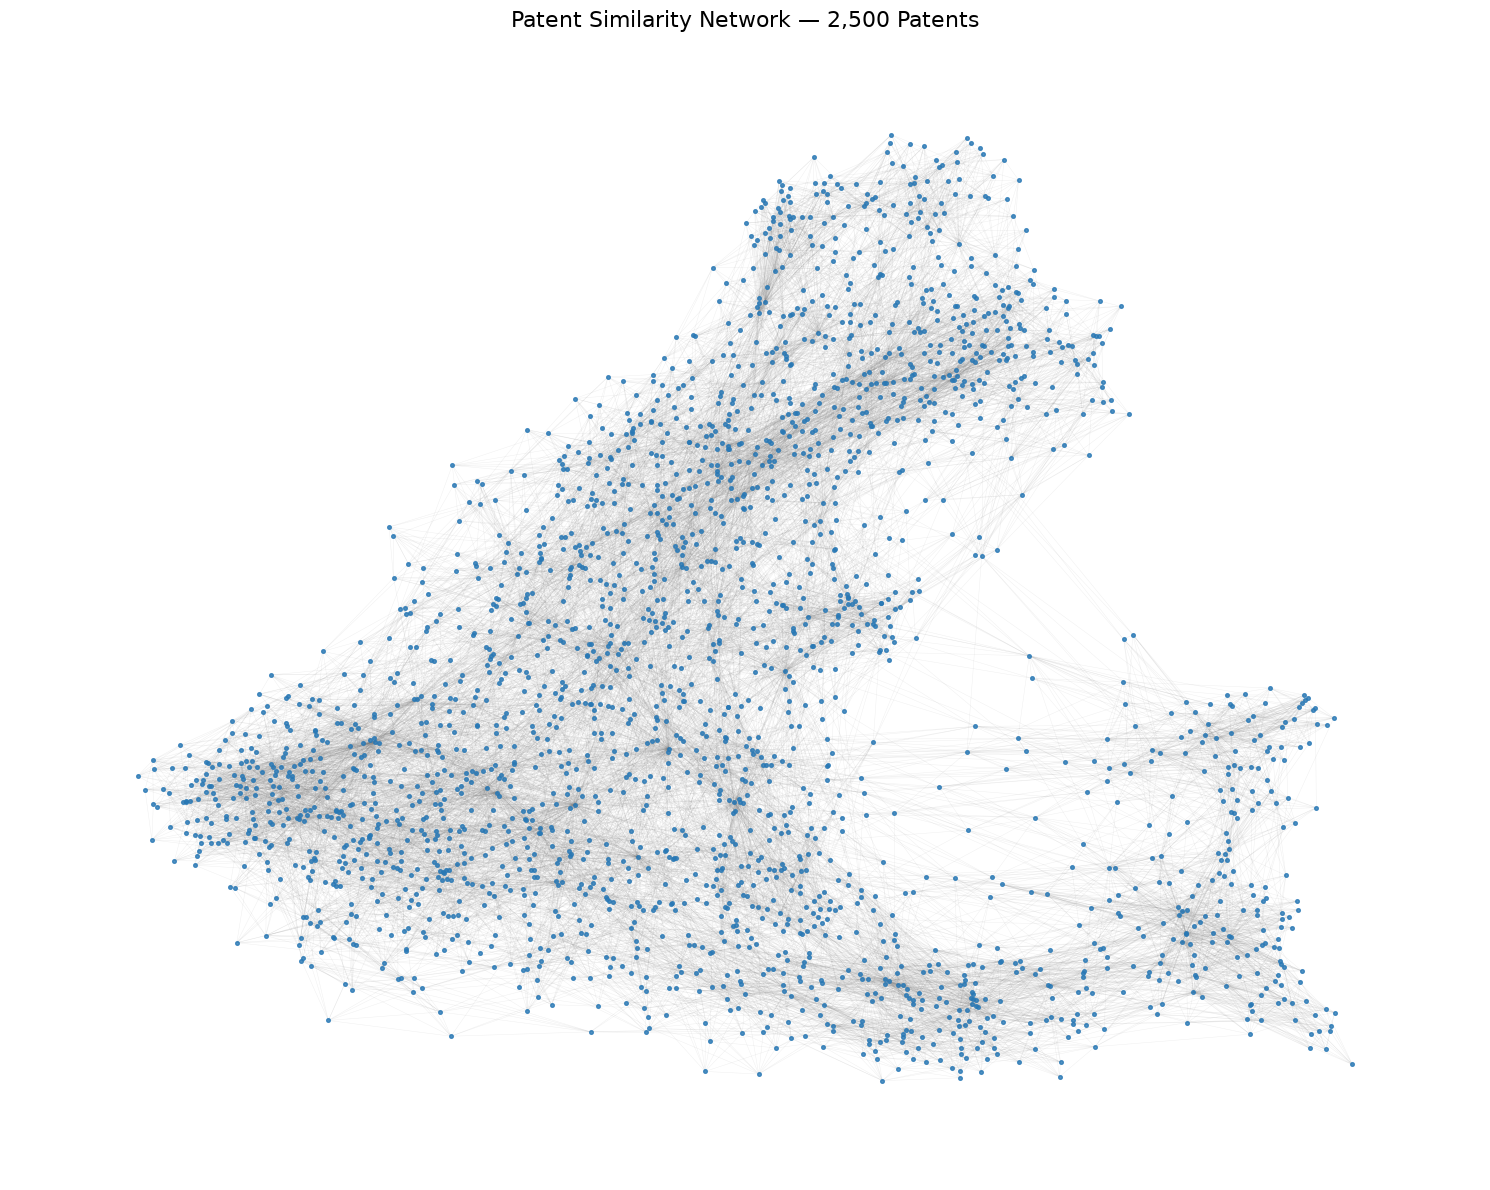

In [14]:
import matplotlib.pyplot as plt
import networkx as nx

# Reproducible force-directed layout
pos = nx.spring_layout(
    G,
    seed=42,
    k=0.15,
    iterations=50,
    weight="weight"
)

plt.figure(figsize=(15, 12))

nx.draw_networkx_edges(
    G,
    pos,
    alpha=0.12,
    width=0.35,
    edge_color="gray"
)

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=7,
    node_color="#2878B5",
    alpha=0.8
)

plt.title(
    "Patent Similarity Network — 2,500 Patents",
    fontsize=16
)
plt.axis("off")
plt.tight_layout()
plt.show()

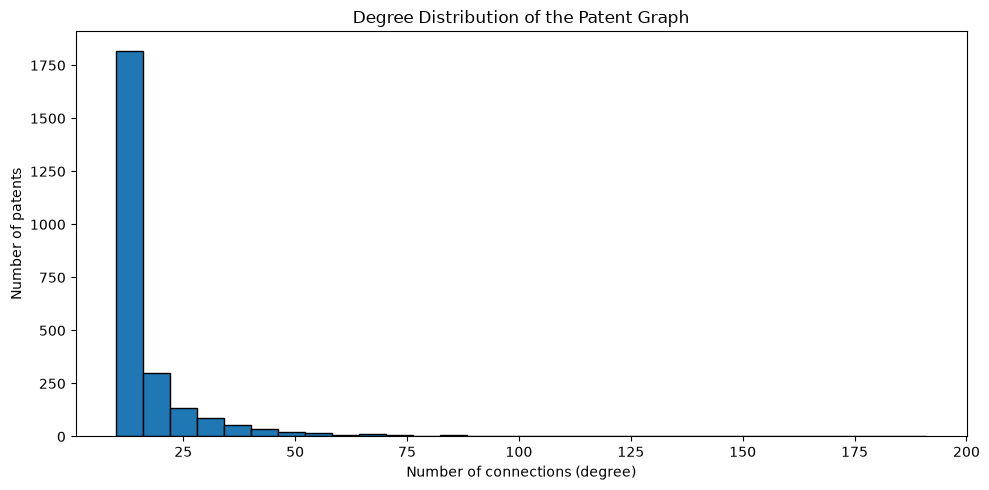

Minimum degree: 10
Maximum degree: 191
Mean degree: 16.6112


In [15]:
degrees = [degree for _, degree in G.degree()]

plt.figure(figsize=(10, 5))
plt.hist(degrees, bins=30, edgecolor="black")
plt.xlabel("Number of connections (degree)")
plt.ylabel("Number of patents")
plt.title("Degree Distribution of the Patent Graph")
plt.tight_layout()
plt.show()

print("Minimum degree:", min(degrees))
print("Maximum degree:", max(degrees))
print("Mean degree:", sum(degrees) / len(degrees))

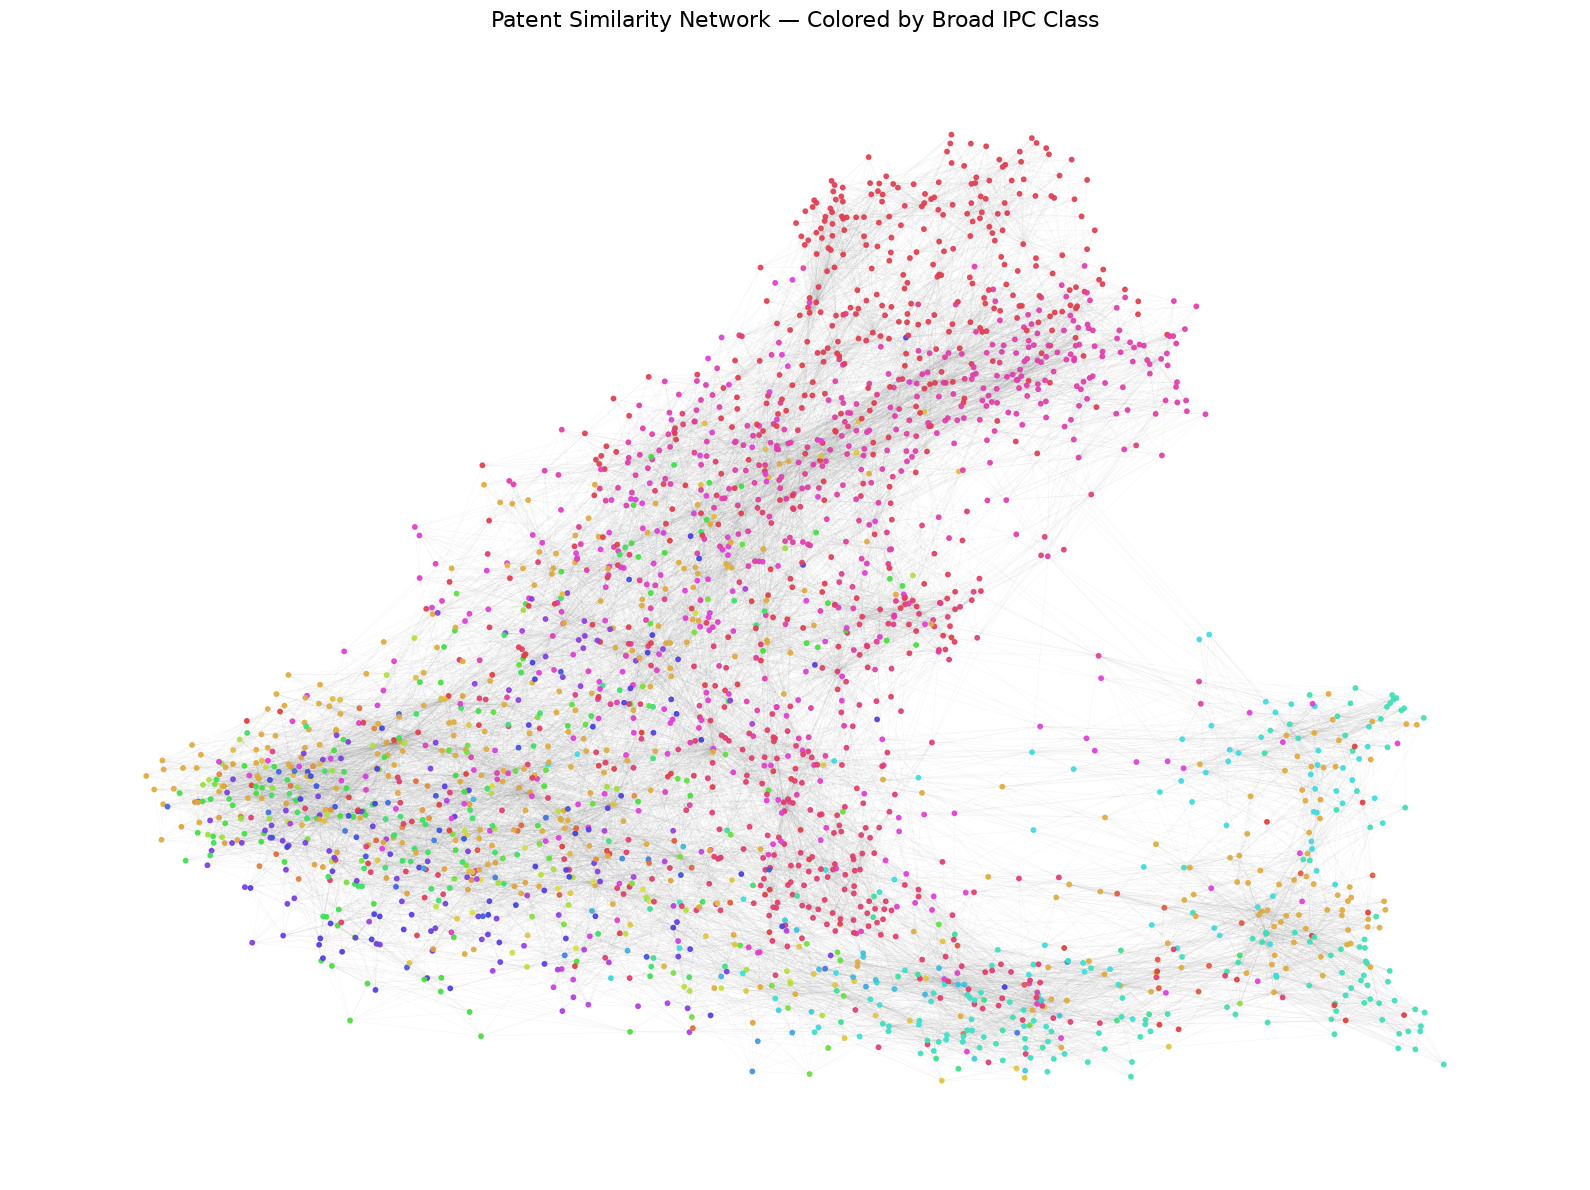

Number of broad IPC classes: 107

Top 15 IPC classes:
H04: 346 patents
G06: 302 patents
A61: 289 patents
H01: 233 patents
G01: 117 patents
C07: 84 patents
B60: 59 patents
H02: 58 patents
G02: 56 patents
C12: 55 patents
F16: 47 patents
B65: 38 patents
H05: 31 patents
B01: 30 patents
C08: 30 patents


In [16]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from collections import Counter
from matplotlib.colors import hsv_to_rgb

# Get the broad IPC class for each patent
def get_ipc_class(attributes):
    label = str(attributes.get("ipc_label", "")).strip().upper()
    if len(label) >= 3 and label[:3].isalnum():
        return label[:3]
    return "Unknown"

ipc_by_node = {
    node: get_ipc_class(attributes)
    for node, attributes in G.nodes(data=True)
}

# Give each class a distinct hue, with related classes
# receiving nearby hues in the sorted class order.
classes = sorted(set(ipc_by_node.values()))
class_to_color = {}

for i, ipc in enumerate(classes):
    hue = i / max(len(classes), 1)
    class_to_color[ipc] = hsv_to_rgb((hue, 0.72, 0.88))

node_colors = [class_to_color[ipc_by_node[node]] for node in G.nodes()]

plt.figure(figsize=(16, 12))

nx.draw_networkx_edges(
    G, pos,
    alpha=0.10,
    width=0.3,
    edge_color="gray"
)

nx.draw_networkx_nodes(
    G, pos,
    node_color=node_colors,
    node_size=10,
    alpha=0.9
)

plt.title("Patent Similarity Network — Colored by Broad IPC Class", fontsize=16)
plt.axis("off")
plt.tight_layout()
plt.show()

# Show the most frequent classes
class_counts = Counter(ipc_by_node.values())
print("Number of broad IPC classes:", len(classes))
print("\nTop 15 IPC classes:")
for ipc, count in class_counts.most_common(15):
    print(f"{ipc}: {count} patents")

In [17]:
from pyvis.network import Network

print("PyVis is ready.")

PyVis is ready.


In [18]:
import pandas as pd

# Create a lookup using the saved sample
patent_details = sample_2016.copy()
patent_details["patent_number"] = (
    patent_details["patent_number"].astype(str)
)
patent_details = patent_details.set_index("patent_number")

# Verify that every graph node has a matching patent record
graph_patent_ids = set(G.nodes())
dataset_patent_ids = set(patent_details.index)

print("Graph nodes:", len(graph_patent_ids))
print("Patent records:", len(dataset_patent_ids))
print("Graph nodes with details:", len(graph_patent_ids & dataset_patent_ids))
print("Missing patent records:", len(graph_patent_ids - dataset_patent_ids))

assert len(graph_patent_ids) == 2500
assert len(graph_patent_ids - dataset_patent_ids) == 0

print("\nPatent details are ready.")

Graph nodes: 2500
Patent records: 2500
Graph nodes with details: 2500
Missing patent records: 0

Patent details are ready.
